# 04 - Tier 3: LLM zero-shot (Claude Haiku 5.5)

Phase 9 (this part): prompt design and configuration, using **training reviews only**. Phase 10 (below, added later) runs the frozen prompt on test300 and the hard cases, with caching and a cost and latency log.

Prompt, schema and model live in `src/llm.py` and are documented in `prompts.md`.

In [1]:
import sys, os, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from src.data_utils import load_split, PROJECT_ROOT
from src.eval_utils import score
from src import llm

print('API key available:', bool(os.getenv('ANTHROPIC_API_KEY')))  # value never printed
print('Model:', llm.MODEL, '| prompt:', llm.PROMPT_VERSION)
client = llm.get_client()
cache = llm.load_cache()  # every API call goes through results/llm_cache.jsonl
print('Cached responses on disk:', len(cache))

API key available: True
Model: claude-haiku-5-5 | prompt: v1


Cached responses on disk: 412


## 1. The prompt
This checks that `prompts.md` documents exactly the prompt the code sends.

In [2]:
active_prompt = llm.SYSTEM_PROMPTS[llm.PROMPT_VERSION]
assert active_prompt in (PROJECT_ROOT / 'prompts.md').read_text(encoding='utf-8'), \
    'prompts.md is out of sync with src/llm.py'
print(active_prompt)
print('\nUser message template:\n' + llm.user_message('<review text>'))

You are a sentiment classifier for movie reviews.
Read the review and decide whether the reviewer's overall opinion of the film is positive or negative.
Every review gets exactly one of these two labels. Reply only with the JSON object required by the output schema.

User message template:
<review>
<review text>
</review>


## 2. Smoke test on hand-written sentences (not from any split)

In [3]:
smoke = ['An absolute delight, I loved every minute.',
         'Two hours of my life I will never get back.']
for s, r in zip(smoke, llm.classify_cached(client, smoke, cache)):
    print(f"{r['label']:>8}  in={r['input_tokens']} out={r['output_tokens']} "
          f"{r['latency_s']:.2f}s  raw={r['raw']}  | {s}")

positive  in=318 out=10 1.50s  raw={"label":"positive"}  | An absolute delight, I loved every minute.
negative  in=317 out=10 1.51s  raw={"label": "negative"}  | Two hours of my life I will never get back.


## 3. Trial on 40 training reviews: thinking off vs adaptive thinking
A stratified sample of 20 positive and 20 negative reviews from **train**. It checks parsing, accuracy, tokens and latency, and whether thinking is worth its extra output tokens. Four requests run in parallel; latency is measured per call.

In [4]:
train = load_split('train')
trial = train.groupby('label').sample(20, random_state=7).reset_index(drop=True)
print(trial['label'].value_counts().to_dict())

def run(texts, **kwargs):
    return llm.classify_cached(client, texts, cache, **kwargs)  # 4 parallel workers on misses

trial_runs = {}
for name, thinking in [('thinking off', False), ('adaptive thinking', True)]:
    trial_runs[name] = pd.DataFrame(run(trial['text'].tolist(), thinking=thinking))

{'negative': 20, 'positive': 20}


In [5]:
summary = []
for name, r in trial_runs.items():
    s = score(trial['label'], r['label'])
    summary.append({
        'config': name,
        'accuracy': s['accuracy'], 'macro_f1': s['macro_f1'],
        'parse_rate': r['parsed'].mean(),
        'mean_in_tokens': r['input_tokens'].mean(),
        'mean_out_tokens': r['output_tokens'].mean(),
        'median_latency_s': r['latency_s'].median(),
        'cost_per_1k_usd': r['cost_usd'].mean() * 1000,
    })
pd.DataFrame(summary).set_index('config').round(4)

,accuracy,macro_f1,parse_rate,mean_in_tokens,mean_out_tokens,median_latency_s,cost_per_1k_usd
config,,,,,,,
thinking off,0.975,0.975,1.0,757.325,10.0,1.1279,0.0807
adaptive thinking,0.975,0.975,1.0,758.325,11.0,1.2904,0.0813


In [6]:
# Trial reviews either config got wrong (training data, so safe to read)
wrong = trial.assign(off=trial_runs['thinking off']['label'],
                     adaptive=trial_runs['adaptive thinking']['label'])
wrong = wrong[(wrong['off'] != wrong['label']) | (wrong['adaptive'] != wrong['label'])]
with pd.option_context('display.max_colwidth', 400):
    display(wrong.assign(text=wrong['text'].str[:400]))

,text,label,off,adaptive
21,"The film largely focuses on a bullying Robert Taylor as a ruthless buffalo hunter and the people who have to put up with him. Set amidst a hunt for dwindling numbers of buffalo, it portrays the end of a tragic era of senseless slaughter and is full of drama and remorse for both the buffalo and the Native Americans. Taylor is blinded by his hatred of Indians and his naivete that the buffalo her...",positive,negative,negative


## 4. Decision

**Frozen configuration for Phase 10:** prompt **v1**, `claude-haiku-5-5`, **thinking off**, structured output.

| Trial (40 train reviews) | Accuracy | Parse rate | Mean in / out tokens | Median latency | Cost / 1k |
|---|---|---|---|---|---|
| Thinking off | 0.975 | 100% | 757 / 10 | 1.14 s | $0.081 |
| Adaptive thinking | 0.975 | 100% | 758 / 11 | 1.30 s | $0.081 |

- **v1 is good enough as written.** It got 39 of 40 right, and every output parsed. Writing a v2 with hints would only risk fitting to known failure patterns, so v1 stays minimal.
- **Thinking off.** With adaptive thinking on, Haiku chose not to think on these reviews (about 1 extra output token), and accuracy was identical. Setting it off explicitly makes the token budget predictable, and it was about 0.15 s faster.
- **The one miss** is a positive review that spends most of its length on a dark plot ("ruthless", "senseless slaughter", "tragic"). It's the same "dark plot summary" pattern that trips VADER.
- **Cost profile.** Even a one-sentence input costs about 318 tokens. That's the fixed overhead of the system prompt plus the structured-output instructions, and it is roughly 40% of an average review's input. Output is always 10 tokens (`{"label":"positive"}`). Input tokens drive the cost: about $0.08 per 1,000 reviews.
- **Expected Phase 10 cost.** 330 calls × about 760 tokens comes to roughly **$0.03** for the whole run.

## 5. Run on test300 and the hard cases
The configuration frozen in §4 is used: prompt v1, Haiku 5.5, thinking off. Every response is appended to `results/llm_cache.jsonl` as it arrives, so the first run makes 330 API calls and later runs make none. The cache stores token counts, latency, cost, stop reason and request id for every call, which makes it the cost and latency log.

In [7]:
from src.data_utils import load_hard_cases
from src.eval_utils import evaluate_model, hard_case_breakdown, METRICS_PATH

test = load_split('test300')
hard = load_hard_cases()

start = time.perf_counter()
test_calls = pd.DataFrame(llm.classify_cached(client, test['text'].tolist(), cache))
hard_calls = pd.DataFrame(llm.classify_cached(client, hard['text'].tolist(), cache))
wall = time.perf_counter() - start

new_calls = int((~test_calls['cached']).sum() + (~hard_calls['cached']).sum())
print(f'API calls this run: {new_calls} new, {len(test_calls) + len(hard_calls) - new_calls} '
      f'from cache; wall-clock {wall:.1f}s (4 parallel workers)')

API calls this run: 0 new, 330 from cache; wall-clock 0.0s (4 parallel workers)


### 5.1 Cost and latency log
Latency is per request, as measured when each call was first made. Seconds per 1k = mean latency × 1,000, i.e. calls made **one at a time**, the same basis as the local models. Parallel throughput is reported separately.

In [8]:
calls = pd.concat([test_calls.assign(split='test300'), hard_calls.assign(split='hard')])
log = calls.groupby('split', sort=False).agg(
    calls=('label', 'size'),
    parse_rate=('parsed', 'mean'),
    mean_in_tokens=('input_tokens', 'mean'),
    mean_out_tokens=('output_tokens', 'mean'),
    total_in_tokens=('input_tokens', 'sum'),
    total_out_tokens=('output_tokens', 'sum'),
    total_cost_usd=('cost_usd', 'sum'),
    median_latency_s=('latency_s', 'median'),
    p90_latency_s=('latency_s', lambda s: s.quantile(0.9)),
    max_latency_s=('latency_s', 'max'),
)
print('Stop reasons:', calls['stop_reason'].value_counts().to_dict())
print('Models     :', calls['model'].value_counts().to_dict())
log.round(4)

Stop reasons: {'end_turn': 330}
Models     : {'claude-haiku-5-5': 330}


,calls,parse_rate,mean_in_tokens,mean_out_tokens,total_in_tokens,total_out_tokens,total_cost_usd,median_latency_s,p90_latency_s,max_latency_s
split,,,,,,,,,,
test300,300,1.0,699.8833,10.0,209965,3000,0.0225,1.1338,1.2331,32.6075
hard,30,1.0,325.7000,10.0,9771,300,0.0011,1.1086,1.1690,1.2121


In [9]:
SEC_PER_1K = test_calls['latency_s'].mean() * 1000
COST_PER_1K = test_calls['cost_usd'].mean() * 1000
PARSE_RATE = test_calls['parsed'].mean()

print(f'Sequential latency : {SEC_PER_1K:,.0f} s per 1k predictions '
      f'({SEC_PER_1K / 60:.1f} min)')
print(f'Parallel throughput: about {SEC_PER_1K / 4:,.0f} s per 1k with 4 workers (rate limits permitting)')
print(f'Cost               : ${COST_PER_1K:.4f} per 1k predictions')
print(f'Total spent (330)  : ${calls["cost_usd"].sum():.4f}')
print(f'Parse rate         : {PARSE_RATE:.1%} (unparsed -> {llm.FALLBACK_LABEL!r})')

Sequential latency : 1,560 s per 1k predictions (26.0 min)
Parallel throughput: about 390 s per 1k with 4 workers (rate limits permitting)
Cost               : $0.0750 per 1k predictions
Total spent (330)  : $0.0236
Parse rate         : 100.0% (unparsed -> 'positive')


### 5.2 Score with the shared harness
Predictions are read from the cache. The predictor fails loudly if scoring would trigger a new API call, so the scored labels are exactly the logged ones.

model                                     LLM zero-shot (Haiku 5.5)
accuracy                                                     0.9567
macro_f1                                                     0.9567
hard_cases_acc                                                  1.0
sec_per_1k                                                 1560.301
cost_per_1k                                                   0.075
n_test                                                          300
n_hard                                                           30
evaluated_at                              2026-11-19T10:25:31+00:00
notes             claude-haiku-5-5, prompt v1, thinking off; par...
dtype: object

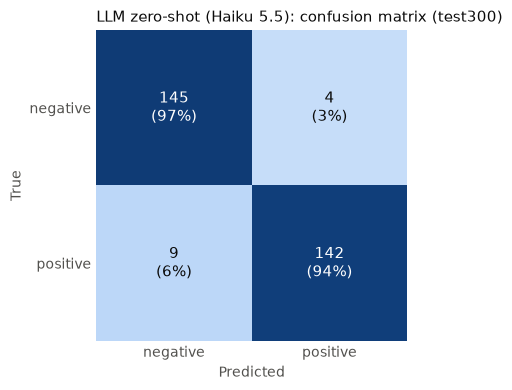

In [10]:
def predict_llm(texts):
    records = llm.classify_cached(client, texts, cache)
    assert all(r['cached'] for r in records), 'unexpected API call during scoring'
    return [r['label'] for r in records]

llm_result = evaluate_model(
    'LLM zero-shot (Haiku 5.5)', predict_llm,
    sec_per_1k=SEC_PER_1K, cost_per_1k=COST_PER_1K,
    notes=(f'{llm.MODEL}, prompt {llm.PROMPT_VERSION}, thinking off; '
           f'parse rate {PARSE_RATE:.1%}; sec/1k = sequential API latency'),
)
pd.Series({k: v for k, v in llm_result.items() if k != 'confusion_matrix'})

In [11]:
hard_case_breakdown('LLM zero-shot (Haiku 5.5)')

,accuracy,correct,n
category,,,
comparison,1.0,2,2
contrast,1.0,3,3
dark_plot_summary,1.0,2,2
domain_polarity,1.0,3,3
double_negative,1.0,2,2
faint_praise,1.0,3,3
idiom,1.0,2,2
negation,1.0,3,3
rating,1.0,2,2


In [12]:
# Hard cases the LLM got wrong (the hand-written set)
hard_view = hard.assign(pred=hard_calls['label'].to_numpy())
with pd.option_context('display.max_colwidth', 100):
    display(hard_view.loc[hard_view['pred'] != hard_view['label'],
                          ['id', 'category', 'label', 'pred', 'text']])

,id,category,label,pred,text


## 6. All tiers so far

In [13]:
pd.read_csv(METRICS_PATH).set_index('model')[
    ['accuracy', 'macro_f1', 'hard_cases_acc', 'sec_per_1k', 'cost_per_1k']]

,accuracy,macro_f1,hard_cases_acc,sec_per_1k,cost_per_1k
model,,,,,
Majority baseline,0.5033,0.3348,0.5000,0.000005,0.000
VADER,0.7267,0.7153,0.3333,4.675349,0.000
TextBlob,0.7100,0.6872,0.4000,2.104080,0.000
NLTK + Naive Bayes,0.8867,0.8867,0.7000,4.183167,0.000
LLM zero-shot (Haiku 5.5),0.9567,0.9567,1.0000,1560.301000,0.075


### Notes

**Results**

| Model | Accuracy | Macro-F1 | Hard-cases acc. | Sec / 1k | Cost / 1k |
|---|---|---|---|---|---|
| VADER | 0.727 | 0.715 | 0.33 | 4.7 | $0 |
| NLTK + Naive Bayes | 0.887 | 0.887 | 0.70 | 4.2 | ~$0 |
| **LLM zero-shot (Haiku 5.5)** | **0.957** | **0.957** | **1.00** | 1,560 | $0.075 |

**Accuracy**
- It gets 287 of 300 right, 7 points above Naive Bayes, with no training data at all.
- Errors lean slightly negative: 9 positive reviews were called negative, against 4 the other way. That's the opposite of VADER's positive bias.
- It got **all 30 hard cases right**, including every category Naive Bayes missed (contrast, idioms, slang/emoji, rhetorical questions, ratings).
- All 330 responses parsed (`end_turn` every time), thanks to structured output. The fallback label was never used.

**Speed**
- Median latency is 1.13 s per call and p90 is 1.23 s. One call took 32.6 s, almost certainly an SDK retry.
- Called **one at a time**, that averages 1.56 s, or **1,560 s per 1,000 reviews (26 minutes)**. That is about 370× slower than Naive Bayes on a laptop CPU.
- With 4 parallel workers the whole run of 330 took 126 s, roughly 390 s per 1,000. More parallelism helps until rate limits apply.

**Cost**
- $0.075 per 1,000 reviews, or about $75 per million. The whole scored run cost $0.024; the full notebook, including the train trial, cost about $0.03.
- Input tokens are 99.5% of the bill: about 700 per review, of which about 318 are fixed overhead. Output is always 10 tokens.

**Caveats to state in the report**
- **The hard cases favour the LLM.** The 30 sentences were written by an LLM (Claude, in Phase 5). They are short and unambiguous, and their style is close to what an LLM produces. They are useful for comparing *failure modes* across tiers, but 30/30 should not be read as "the LLM never fails on sarcasm".
- **Possible contamination.** IMDB reviews are public and very likely in Haiku's pretraining data. Naive Bayes saw 40K of them explicitly, so the comparison is still fair in spirit, but zero-shot accuracy on truly unseen domains may be lower.
- **Not exactly reproducible.** Sampling can't be fixed on current models (no `temperature`). Re-running against the API could change a few labels, which is why the cached responses are the record of truth.